# Used-Vehicle Price Prediction in Sri Lanka
### Comparative Ensemble Regression and Model Evaluation

**MSc Machine Learning · Final Assignment**  
**Target:** Advertised vehicle price (LKR) · **Random seed:** 42

## 1. Dataset and experimental environment

The cleaned dataset from Notebook 01 is used for all regression experiments.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

SEED = 42
sns.set_theme(style='whitegrid', palette='deep', context='notebook')
plt.rcParams.update({'figure.figsize':(9,4.5), 'axes.spines.top':False,
                     'axes.spines.right':False,'figure.dpi':110})
pd.set_option('display.max_columns',25)

In [2]:
PROJECT_FOLDERS = [
    'Sri_Lanka_Vehicle_Price_Final_Assignment',
    'Sri_Lanka_Vehicle_Price_Final_Assignment_Submission',
    'Sri_Lanka_Vehicle_Price_Jupyter_Notebooks',
]
DRIVE_ROOT = Path('/content/drive/MyDrive')

if Path('/content').exists() and not DRIVE_ROOT.exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass

candidates = [
    Path.cwd(),
    *(DRIVE_ROOT / folder for folder in PROJECT_FOLDERS),
    Path('/content'),
    Path('/mnt/data'),
]
PROJECT_DIR = next(
    (folder for folder in candidates
     if (folder / 'vehicle_ml_outputs' / 'cleaned_vehicle_data.csv').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Cleaned dataset not found. Execute Notebook 01 first.')

OUTPUT_DIR = PROJECT_DIR / 'vehicle_ml_outputs'
CLEAN_CSV = OUTPUT_DIR / 'cleaned_vehicle_data.csv'
TARGET = 'PriceLKR'
CAT = ['Brand', 'Model', 'Edition', 'Transmission', 'FuelType', 'BodyType', 'Negotiable']
NUM = ['ManufactureYear', 'EngineCC', 'MileageKM']
FEATURES = CAT + NUM

df = pd.read_csv(CLEAN_CSV)
assert set(FEATURES + [TARGET]).issubset(df.columns)
for column in CAT:
    df[column] = df[column].fillna('Unknown').astype(str)
for column in NUM + [TARGET]:
    df[column] = pd.to_numeric(df[column], errors='coerce')
assert df[TARGET].notna().all() and df[TARGET].gt(0).all() and len(df) > 1000

profile = pd.DataFrame({
    'Observations': [len(df)],
    'Predictors': [len(FEATURES)],
    'Median price (LKR)': [df[TARGET].median()],
    'Missing numeric cells': [int(df[NUM].isna().sum().sum())],
})
display(profile.style.format({'Median price (LKR)': '{:,.0f}'}).hide(axis='index'))
display(df.head(4))

Observations,Predictors,Median price (LKR),Missing numeric cells
8554,10,"10,690,000",115


,Brand,Model,Edition,Transmission,FuelType,BodyType,Negotiable,ManufactureYear,EngineCC,MileageKM,PriceLKR
0,Audi,A3,Unknown,Automatic,Petrol,Saloon,Yes,2023,1500.0,0.0,20500000.0
1,Audi,A3,Sport Back S Line,Automatic,Petrol,Hatchback,Yes,2023,1000.0,11000.0,18500000.0
2,Ford,Laser,Gl,Manual,Petrol,Saloon,Yes,1988,1500.0,250000.0,1000000.0
3,Honda,Clarity,Unknown,Manual,Petrol,Coupé/Sports,Yes,2005,1000.0,20000.0,1000000.0


## 2. Partitioning and leakage controls

`GroupShuffleSplit` assigns identical feature combinations to disjoint training, validation and test partitions (approximately 70% / 15% / 15%).

In [3]:
feature_groups = pd.util.hash_pandas_object(df[FEATURES],index=False)
outer = GroupShuffleSplit(n_splits=1,test_size=.15,random_state=SEED)
trainval_idx,test_idx = next(outer.split(df,groups=feature_groups))
inner = GroupShuffleSplit(n_splits=1,test_size=.17647,random_state=SEED+1)
train_local,val_local = next(inner.split(trainval_idx,groups=feature_groups.iloc[trainval_idx]))
train_idx,val_idx = trainval_idx[train_local],trainval_idx[val_local]

g_train=set(feature_groups.iloc[train_idx]);g_val=set(feature_groups.iloc[val_idx]);g_test=set(feature_groups.iloc[test_idx])
assert g_train.isdisjoint(g_val) and g_train.isdisjoint(g_test) and g_val.isdisjoint(g_test)
X_train,y_train = df.iloc[train_idx][FEATURES],df.iloc[train_idx][TARGET]
X_val,y_val = df.iloc[val_idx][FEATURES],df.iloc[val_idx][TARGET]
X_trainval,y_trainval = df.iloc[trainval_idx][FEATURES],df.iloc[trainval_idx][TARGET]
X_test,y_test = df.iloc[test_idx][FEATURES],df.iloc[test_idx][TARGET]
cv_groups = feature_groups.iloc[train_idx]

partition = pd.DataFrame({'Partition':['Train','Validation','Test'],
                          'Rows':[len(train_idx),len(val_idx),len(test_idx)],
                          'Unique groups':[len(g_train),len(g_val),len(g_test)]})
display(partition.style.format({'Rows':'{:,}','Unique groups':'{:,}'}).hide(axis='index'))

Partition,Rows,Unique groups
Train,"5,995","5,810"
Validation,"1,274","1,245"
Test,"1,285","1,246"


## 3. Feature preprocessing and target transformation

Training-fold preprocessing uses median imputation, robust scaling and rare-category-aware one-hot encoding. The regression target is log-transformed; predictions are returned in LKR.

In [4]:
def make_pipeline(regressor):
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', RobustScaler(with_centering=False)),
    ])
    categorical = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(
            handle_unknown='infrequent_if_exist',
            min_frequency=15,
            sparse_output=True,
        )),
    ])
    preprocess = ColumnTransformer([
        ('numeric', numeric, NUM),
        ('categorical', categorical, CAT),
    ], sparse_threshold=1.0)
    model = Pipeline([
        ('preprocess', preprocess),
        ('regressor', regressor),
    ])
    return TransformedTargetRegressor(
        regressor=model,
        func=np.log1p,
        inverse_func=np.expm1,
    )

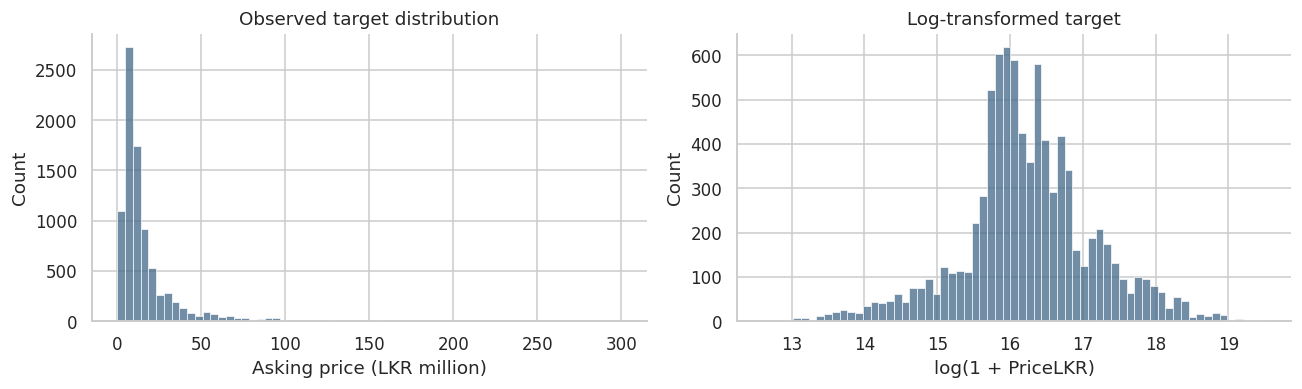

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
sns.histplot(df.PriceLKR / 1e6, bins=65, ax=axes[0], color='#416989')
axes[0].set(xlabel='Asking price (LKR million)', title='Observed target distribution')
sns.histplot(np.log1p(df.PriceLKR), bins=65, ax=axes[1], color='#416989')
axes[1].set(xlabel='log(1 + PriceLKR)', title='Log-transformed target')
plt.tight_layout()
plt.show()

## 4. Regression candidates and evaluation metrics

The comparison includes a median baseline, a Decision Tree and three tree-ensemble approaches.

In [6]:
estimators = {
    'Median baseline': DummyRegressor(strategy='median'),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=18, min_samples_leaf=4, min_samples_split=10,
        random_state=SEED,
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=160, max_depth=24, min_samples_leaf=2,
        min_samples_split=4, max_features=.85, n_jobs=2,
        random_state=SEED,
    ),
    'XGBoost': XGBRegressor(
        n_estimators=450, max_depth=7, learning_rate=.055,
        min_child_weight=3, subsample=.85, colsample_bytree=.85,
        reg_lambda=4, tree_method='hist', objective='reg:squarederror',
        n_jobs=2, random_state=SEED,
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=380, num_leaves=31, max_depth=10,
        learning_rate=.05, min_child_samples=25, subsample=.9,
        subsample_freq=1, colsample_bytree=.85, reg_lambda=3,
        verbose=-1, n_jobs=2, random_state=SEED,
    ),
}

pd.DataFrame([
    {'Model': name, 'Estimator': type(estimator).__name__}
    for name, estimator in estimators.items()
])

,Model,Estimator
0,Median baseline,DummyRegressor
1,Decision Tree,DecisionTreeRegressor
2,Random Forest,RandomForestRegressor
3,XGBoost,XGBRegressor
4,LightGBM,LGBMRegressor


In [7]:
def metrics(y_true, y_pred):
    y_pred = np.maximum(np.asarray(y_pred), 0)
    return {
        'MAE_LKR': mean_absolute_error(y_true, y_pred),
        'RMSE_LKR': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
        'Median_APE_pct': np.median(
            np.abs(np.asarray(y_true) - y_pred)
            / np.maximum(np.asarray(y_true), 1)
        ) * 100,
    }

## 5. Initial validation comparison

Each candidate is trained on the training partition and evaluated on validation MAE, RMSE and R².

In [8]:
validation_rows=[]
base_fitted={}
for name,est in estimators.items():
    t0=time.perf_counter()
    fitted=make_pipeline(est).fit(X_train,y_train)
    scores=metrics(y_val,fitted.predict(X_val))
    validation_rows.append({'Model':name,**scores,'Fit_s':time.perf_counter()-t0,'Experiment':'Configured'})
    base_fitted[name]=fitted
validation=pd.DataFrame(validation_rows).sort_values('MAE_LKR').reset_index(drop=True)
display(validation.style.format({'MAE_LKR':'{:,.0f}','RMSE_LKR':'{:,.0f}',
                                 'R2':'{:.3f}','Median_APE_pct':'{:.1f}',
                                 'Fit_s':'{:.1f}'}).background_gradient(subset=['MAE_LKR'],cmap='Blues_r'))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,MAE_LKR,RMSE_LKR,R2,Median_APE_pct,Fit_s,Experiment
0,XGBoost,"1,947,558","5,728,231",0.919,6.0,0.6,Configured
1,Random Forest,"2,029,289","7,426,212",0.864,5.6,7.2,Configured
2,LightGBM,"2,202,386","6,772,247",0.887,6.7,0.4,Configured
3,Decision Tree,"2,588,351","10,110,665",0.748,6.6,0.1,Configured
4,Median baseline,"10,694,016","21,264,576",-0.114,44.2,0.1,Configured


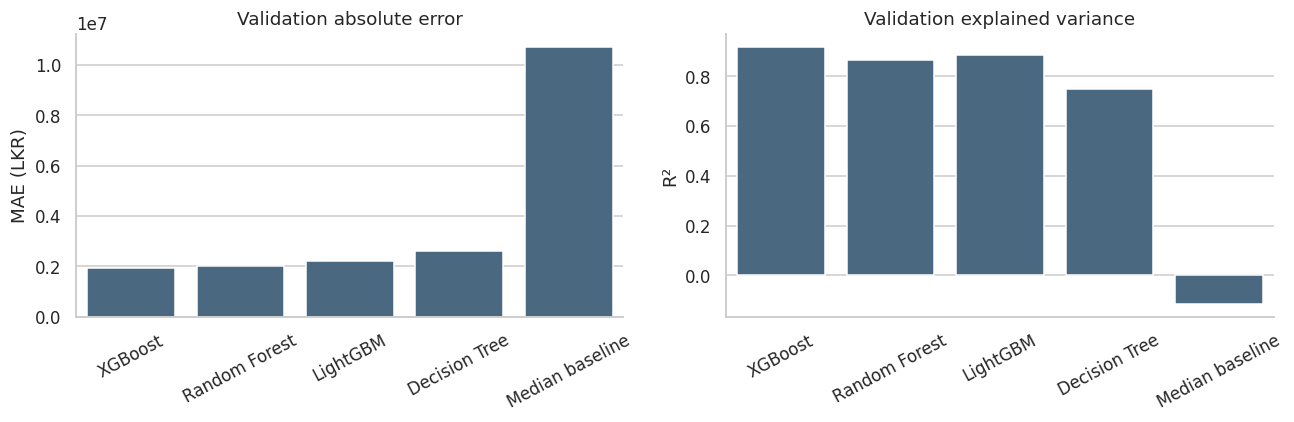

In [9]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=validation,x='Model',y='MAE_LKR',ax=ax[0],color='#416989')
ax[0].set(title='Validation absolute error',ylabel='MAE (LKR)',xlabel='')
sns.barplot(data=validation,x='Model',y='R2',ax=ax[1],color='#416989')
ax[1].set(title='Validation explained variance',ylabel='R²',xlabel='')
for a in ax:a.tick_params(axis='x',labelrotation=28)
plt.tight_layout();plt.show()

## 6. Group-aware cross-validation and tuning

The two strongest ensemble candidates undergo three-fold `GroupKFold` and a compact `RandomizedSearchCV` (three parameter combinations each).

In [10]:
ensemble_names=['Random Forest','XGBoost','LightGBM']
ranked_ensembles=[x for x in validation.Model if x in ensemble_names]
search_names=ranked_ensembles[:2]
search_spaces={
 'Random Forest':{'regressor__regressor__n_estimators':[120,200,260],
                  'regressor__regressor__max_depth':[16,24,None],
                  'regressor__regressor__min_samples_leaf':[1,2,4]},
 'XGBoost':{'regressor__regressor__n_estimators':[280,450,650],
            'regressor__regressor__max_depth':[4,6,8],
            'regressor__regressor__learning_rate':[.035,.055,.08],
            'regressor__regressor__min_child_weight':[2,4,6]},
 'LightGBM':{'regressor__regressor__n_estimators':[260,380,520],
             'regressor__regressor__num_leaves':[15,31,48],
             'regressor__regressor__min_child_samples':[15,25,40],
             'regressor__regressor__learning_rate':[.035,.05,.08]}
}
cv=GroupKFold(n_splits=3)
searches={}
cv_results=[]
for name in search_names:
    search=RandomizedSearchCV(make_pipeline(estimators[name]),
          param_distributions=search_spaces[name],n_iter=3,scoring='neg_mean_absolute_error',
          cv=cv,n_jobs=1,refit=True,random_state=SEED,verbose=0)
    search.fit(X_train,y_train,groups=cv_groups)
    searches[name]=search
    cv_results.append({'Model':name,'CV_MAE_LKR':-search.best_score_,
        'CV_MAE_SD_LKR':search.cv_results_['std_test_score'][search.best_index_],
        'Best_settings':str({k.split('__')[-1]:v for k,v in search.best_params_.items()})})
cv_report=pd.DataFrame(cv_results).sort_values('CV_MAE_LKR')
display(cv_report.style.format({'CV_MAE_LKR':'{:,.0f}','CV_MAE_SD_LKR':'{:,.0f}'}).hide(axis='index'))
cv_report.to_csv(OUTPUT_DIR/'cross_validation_results.csv',index=False)

Model,CV_MAE_LKR,CV_MAE_SD_LKR,Best_settings
Random Forest,"2,044,119","85,996","{'n_estimators': 120, 'min_samples_leaf': 1, 'max_depth': 24}"
XGBoost,"2,082,394","104,781","{'n_estimators': 450, 'min_child_weight': 4, 'max_depth': 8, 'learning_rate': 0.035}"


## 7. Model selection

The final model is selected by **validation MAE**; the test set is excluded from selection.

In [11]:
selection_rows=validation.copy().to_dict('records')
model_options={r['Model']:base_fitted[r['Model']] for r in selection_rows}
for name,search in searches.items():
    tuned_name=f'{name} · tuned'
    model_options[tuned_name]=search.best_estimator_
    selection_rows.append({'Model':tuned_name,**metrics(y_val,search.predict(X_val)),
                           'Fit_s':np.nan,'Experiment':'CV tuned'})
selection=pd.DataFrame(selection_rows).sort_values('MAE_LKR').reset_index(drop=True)
winning_name=selection.loc[0,'Model']
selected_template=model_options[winning_name]
display(selection[['Model','Experiment','MAE_LKR','RMSE_LKR','R2']].style.format(
    {'MAE_LKR':'{:,.0f}','RMSE_LKR':'{:,.0f}','R2':'{:.3f}'}).background_gradient(
    subset=['MAE_LKR'],cmap='Blues_r'))
display(Markdown(f'**Validation-selected model: {winning_name}**'))
selection.to_csv(OUTPUT_DIR/'validation_metrics.csv',index=False)

,Model,Experiment,MAE_LKR,RMSE_LKR,R2
0,XGBoost · tuned,CV tuned,"1,924,062","5,785,612",0.918
1,Random Forest · tuned,CV tuned,"1,941,919","7,330,317",0.868
2,XGBoost,Configured,"1,947,558","5,728,231",0.919
3,Random Forest,Configured,"2,029,289","7,426,212",0.864
4,LightGBM,Configured,"2,202,386","6,772,247",0.887
5,Decision Tree,Configured,"2,588,351","10,110,665",0.748
6,Median baseline,Configured,"10,694,016","21,264,576",-0.114


**Validation-selected model: XGBoost · tuned**

## 8. Held-out test evaluation

The selected configuration is refitted on training plus validation data. The unchanged test partition is then evaluated.

In [12]:
from sklearn.base import clone
final_models={}
test_preds={}
final_rows=[]
final_names=list(estimators.keys())
if winning_name not in final_names:final_names.append(winning_name)
for name in final_names:
    candidate=selected_template if name==winning_name else model_options[name]
    fitted=clone(candidate).fit(X_trainval,y_trainval)
    predicted=np.maximum(fitted.predict(X_test),0)
    final_models[name]=fitted
    test_preds[name]=predicted
    final_rows.append({'Model':name,**metrics(y_test,predicted),'Observations':len(y_test)})
test_metrics=pd.DataFrame(final_rows).sort_values('MAE_LKR').reset_index(drop=True)
selected_model=final_models[winning_name]
selected_preds=test_preds[winning_name]
display(test_metrics.style.format({'MAE_LKR':'{:,.0f}','RMSE_LKR':'{:,.0f}',
                                   'R2':'{:.3f}','Median_APE_pct':'{:.1f}'}).background_gradient(
                                   subset=['MAE_LKR'],cmap='Blues_r'))
test_metrics.to_csv(OUTPUT_DIR/'test_metrics.csv',index=False)

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,MAE_LKR,RMSE_LKR,R2,Median_APE_pct,Observations
0,Random Forest,"1,872,571","6,697,868",0.900,5.4,1285
1,XGBoost,"1,951,965","6,811,587",0.897,6.0,1285
2,XGBoost · tuned,"1,973,477","6,851,383",0.896,5.9,1285
3,LightGBM,"2,163,140","7,127,195",0.887,6.7,1285
4,Decision Tree,"2,199,151","7,487,122",0.875,6.3,1285
5,Median baseline,"10,531,084","22,199,013",-0.095,43.3,1285


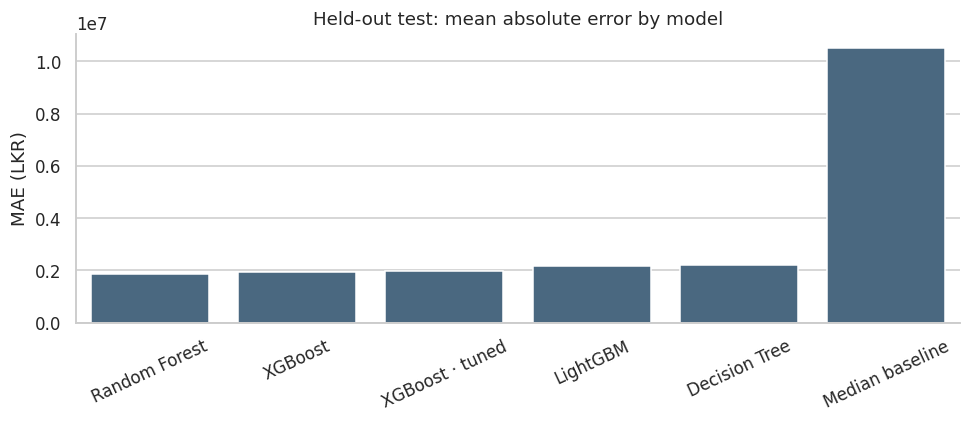

In [13]:
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(data=test_metrics,x='Model',y='MAE_LKR',color='#416989',ax=ax)
ax.set(title='Held-out test: mean absolute error by model',xlabel='',ylabel='MAE (LKR)')
ax.tick_params(axis='x',labelrotation=25)
plt.tight_layout();plt.show()
fig.savefig(OUTPUT_DIR/'test_model_comparison.png',dpi=160,bbox_inches='tight')

## 9. Prediction error analysis

Residuals and MAE are examined across observed asking-price bands.

PriceBand,Records,MAE_LKR,MedianPriceLKR
Below 10M,601,"581,477","6,900,000"
10M–30M,514,"1,353,958","14,350,000"
30M–100M,156,"7,209,764","42,750,000"
100M+,14,"26,128,033","147,500,000"


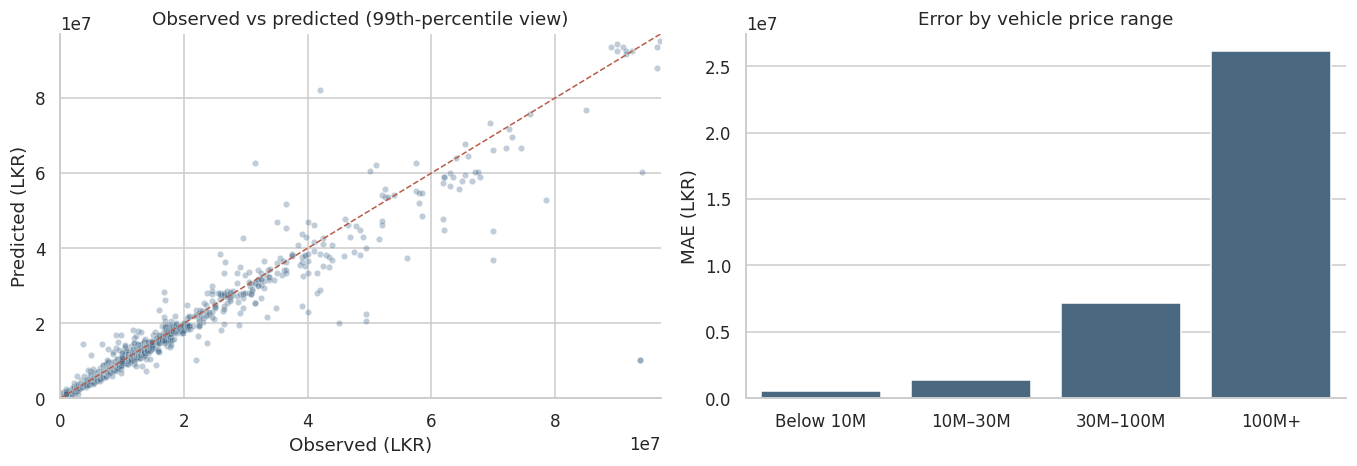

In [14]:
predictions_df=X_test.reset_index(drop=True).copy()
predictions_df['ActualLKR']=y_test.to_numpy()
predictions_df['PredictedLKR']=selected_preds
predictions_df['AbsoluteErrorLKR']=np.abs(predictions_df.ActualLKR-predictions_df.PredictedLKR)
predictions_df['ResidualLKR']=predictions_df.ActualLKR-predictions_df.PredictedLKR
predictions_df['PriceBand']=pd.cut(predictions_df.ActualLKR,
    bins=[0,10e6,30e6,100e6,np.inf],right=False,
    labels=['Below 10M','10M–30M','30M–100M','100M+'])
error_bands=predictions_df.groupby('PriceBand',observed=True).agg(
    Records=('ActualLKR','size'),MAE_LKR=('AbsoluteErrorLKR','mean'),
    MedianPriceLKR=('ActualLKR','median')).reset_index()
display(error_bands.style.format({'MAE_LKR':'{:,.0f}','MedianPriceLKR':'{:,.0f}'}).hide(axis='index'))
fig,ax=plt.subplots(1,2,figsize=(12.5,4.4))
limit=np.quantile(predictions_df[['ActualLKR','PredictedLKR']].to_numpy(),.99)
sns.scatterplot(data=predictions_df,x='ActualLKR',y='PredictedLKR',
                color='#416989',alpha=.33,s=17,ax=ax[0])
ax[0].plot([0,limit],[0,limit],'--',color='#b85c48',lw=1)
ax[0].set(xlim=(0,limit),ylim=(0,limit),title='Observed vs predicted (99th-percentile view)',
          xlabel='Observed (LKR)',ylabel='Predicted (LKR)')
sns.barplot(data=error_bands,x='PriceBand',y='MAE_LKR',color='#416989',ax=ax[1])
ax[1].set(title='Error by vehicle price range',xlabel='',ylabel='MAE (LKR)')
plt.tight_layout();plt.show()
fig.savefig(OUTPUT_DIR/'test_model_diagnostics.png',dpi=160,bbox_inches='tight')
predictions_df.to_csv(OUTPUT_DIR/'test_price_predictions.csv',index=False)
error_bands.to_csv(OUTPUT_DIR/'error_by_price_band.csv',index=False)

## 10. Feature importance

Permutation importance quantifies the change in validation MAE when each feature is shuffled; it does not establish causality.

Feature,MAE_Increase_LKR,SD_LKR
EngineCC,"11,059,471","506,060"
ManufactureYear,"4,318,420","212,422"
Brand,"2,634,130","36,449"
MileageKM,"1,727,209","31,744"
Transmission,"861,499","89,651"
Model,"778,966","4,982"
BodyType,"590,788","128,524"
FuelType,"475,197","7,545"
Edition,"117,062","40,365"
Negotiable,"49,868","10,822"


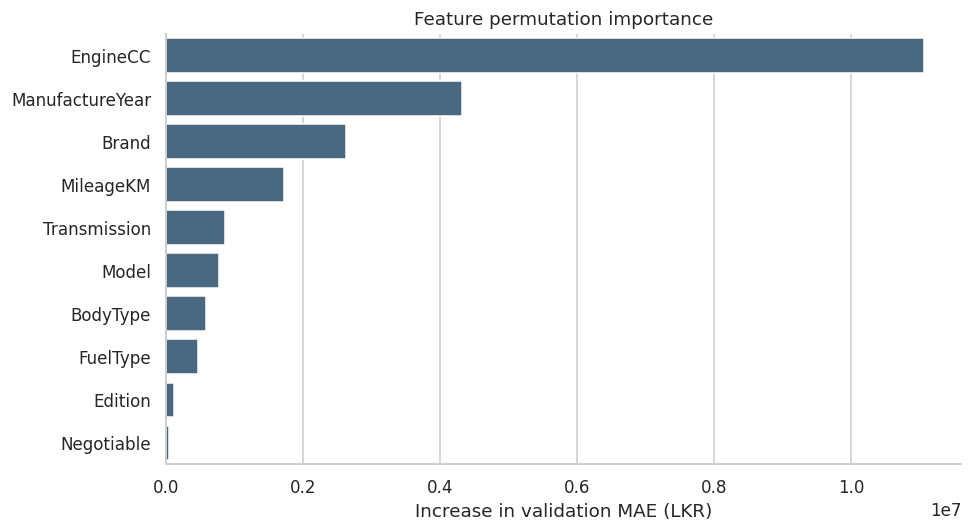

In [15]:
interpretation_model=model_options[winning_name]
rng=np.random.default_rng(SEED)
ix=rng.choice(len(X_val),min(450,len(X_val)),replace=False)
importance=permutation_importance(interpretation_model,X_val.iloc[ix],y_val.iloc[ix],
    scoring='neg_mean_absolute_error',n_repeats=2,random_state=SEED,n_jobs=1)
importance_df=pd.DataFrame({'Feature':FEATURES,
    'MAE_Increase_LKR':importance.importances_mean,'SD_LKR':importance.importances_std})
importance_df=importance_df.sort_values('MAE_Increase_LKR',ascending=False)
display(importance_df.style.format({'MAE_Increase_LKR':'{:,.0f}','SD_LKR':'{:,.0f}'}).hide(axis='index'))
fig,ax=plt.subplots(figsize=(9,5))
sns.barplot(data=importance_df,y='Feature',x='MAE_Increase_LKR',color='#416989',ax=ax)
ax.set(xlabel='Increase in validation MAE (LKR)',ylabel='',title='Feature permutation importance')
plt.tight_layout();plt.show()
fig.savefig(OUTPUT_DIR/'feature_importance.png',dpi=160,bbox_inches='tight')
importance_df.to_csv(OUTPUT_DIR/'feature_importance.csv',index=False)

## 11. Export and inference verification

The fitted preprocessing-and-regression pipeline is saved and reloaded for a single-record prediction.

In [16]:
MODEL_PATH = OUTPUT_DIR / 'trained_vehicle_price_model.pkl'
joblib.dump(selected_model, MODEL_PATH)
reloaded_model = joblib.load(MODEL_PATH)

example = X_test.iloc[[0]].copy()
actual_price = float(y_test.iloc[0])
predicted_price = max(float(reloaded_model.predict(example)[0]), 0)

assert np.isfinite(predicted_price)
assert np.allclose(
    reloaded_model.predict(X_test.iloc[:3]),
    selected_model.predict(X_test.iloc[:3]),
)

comparison = pd.DataFrame({
    'Actual asking price (LKR)': [actual_price],
    'Predicted price (LKR)': [predicted_price],
    'Absolute error (LKR)': [abs(predicted_price - actual_price)],
})
display(example[FEATURES])
display(comparison.style.format('{:,.0f}').hide(axis='index'))

,Brand,Model,Edition,Transmission,FuelType,BodyType,Negotiable,ManufactureYear,EngineCC,MileageKM
14,Nissan,March,K10,Manual,Petrol,Hatchback,Yes,1986,996.0,115000.0


Actual asking price (LKR),Predicted price (LKR),Absolute error (LKR)
"1,050,000","816,389","233,611"


### Example prediction

A separate input record checks the deployed model's feature schema.

In [17]:
new_vehicle = pd.DataFrame([{
    'Brand': 'Toyota',
    'Model': 'Aqua',
    'Edition': 'Unknown',
    'Transmission': 'Automatic',
    'FuelType': 'Hybrid',
    'BodyType': 'Hatchback',
    'Negotiable': 'Yes',
    'ManufactureYear': 2017,
    'EngineCC': 1500,
    'MileageKM': 85000,
}])
new_prediction = float(reloaded_model.predict(new_vehicle)[0])
display(pd.DataFrame({
    'Vehicle': ['Toyota Aqua (illustrative input)'],
    'Predicted asking price (LKR)': [round(max(new_prediction, 0))],
}).style.format({'Predicted asking price (LKR)': '{:,.0f}'}).hide(axis='index'))

Vehicle,Predicted asking price (LKR)
Toyota Aqua (illustrative input),"10,082,561"


In [18]:
metadata = {
    'source': 'KDU Ikman scrape (advertised asking prices)',
    'model': winning_name,
    'selected_on': 'validation MAE only',
    'target': TARGET,
    'numeric_features': NUM,
    'categorical_features': CAT,
    'n_raw_cleaned': int(len(df)),
    'split_counts': {
        'train': len(train_idx),
        'validation': len(val_idx),
        'test': len(test_idx),
    },
    'test_metrics': test_metrics.to_dict('records'),
    'price_unit': 'LKR',
    'note': 'Predicts listing asking prices, not transacted market values',
}
(OUTPUT_DIR / 'model_metadata.json').write_text(
    json.dumps(metadata, indent=2), encoding='utf-8'
)
print('Saved model:', MODEL_PATH)
print('Saved metadata:', OUTPUT_DIR / 'model_metadata.json')

Saved model: /mnt/data/vehicle_ml_outputs/trained_vehicle_price_model.pkl
Saved metadata: /mnt/data/vehicle_ml_outputs/model_metadata.json


## 12. Experimental conclusion

Performance is reported on disjoint test observations. Results refer to advertised prices rather than confirmed transactions.

In [19]:
selected_test=test_metrics.loc[test_metrics.Model.eq(winning_name)].iloc[0]
final_summary=pd.DataFrame({
    'Measure':['Selected model','Test observations','Test MAE (LKR)',
               'Test RMSE (LKR)','Test R²','Median absolute percentage error'],
    'Result':[winning_name,f'{len(y_test):,}',f'{selected_test.MAE_LKR:,.0f}',
              f'{selected_test.RMSE_LKR:,.0f}',f'{selected_test.R2:.3f}',
              f'{selected_test.Median_APE_pct:.1f}%']})
display(final_summary.style.hide(axis='index'))

Measure,Result
Selected model,XGBoost · tuned
Test observations,"1,285"
Test MAE (LKR),"1,973,477"
Test RMSE (LKR),"6,851,383"
Test R²,0.896
Median absolute percentage error,5.9%


**Limitations.** Historical listing dates and advertisement IDs are unavailable; reposted listings may remain. Error varies substantially by price band, especially for high-value vehicles. The serialized pipeline is deployed separately using Streamlit.